# Uplift Simulation: Why predicting who will buy is not the same as predicting who to discount

Data scientists often build a propensity model to decide who receives an offer: score every account on its probability of buying, then send the discount to the top of the list. The logic feels natural, but it answers the wrong question. The decision is not who will buy. The decision is who will buy **because** of the discount, and whether that is worth what the discount costs.

In this notebook I simulate a company that just merged with a data transformation company and wants to offer a discounted bundle of both products. The unit of analysis is the **account**. I follow a five step targeting framework: define the population and the constraint, define the treatment effect of interest, write the expected profit comparison, estimate the effect from a randomized pilot, and target where the comparison favors treating.

## Step 1: Population and constraint

The population is every existing account. The intervention is a discounted bundle offer. There is no hard audience cap, but the intervention is costly: an account that adopts the bundle contributes a margin of $V = 100$ (I am assuming the same margin for all accounts, but this may vary in real life), and the discount gives away $d = 20$ of that margin on every account that adopts after receiving the offer. The constraint is therefore a profitability threshold that the offer must clear for each account. I also report results under a budget cap, ranking accounts and treating only the top share, because that is the more common practical version of the question.

## Step 2: Treatment effect of interest

For each account, the effect of interest is the **uplift**, not the propensity:

$$\tau_i = P(Y_i = 1 \mid W_i = 1, X_i) - P(Y_i = 1 \mid W_i = 0, X_i) = p_i^1 - p_i^0$$

where $Y_i$ indicates whether the account adopts the bundle within 90 days, $W_i$ indicates whether the account received the offer, and $X_i$ denotes the account characteristics.

## Step 3: Expected profit comparison

The offer should be made to account $i$ only when expected profit with the offer exceeds expected profit without it:

$$p_i^1\,(V - d) \;>\; p_i^0\,V \quad\Longleftrightarrow\quad \tau_i\,V > p_i^1\,d$$

The right hand side $(p_i^1\,d)$ is the cannibalization cost. An account that would have adopted anyway still receives the discount, so a high baseline probability (i.e higher propensity) makes the offer expensive even when the account is likely to buy. This is why discounting the most likely buyers can produce lower expected profit than doing nothing.

## Data Generating Process

Each account $i$ has six observable characteristics:

$$\ln S_i \sim N(2.5,\ 1) \qquad U_i \sim \text{Bernoulli}(0.35) \qquad G_i \sim N(0,\ 1)$$
$$M_i \sim \text{Exponential}(24) \qquad R_i \sim \text{Bernoulli}(0.2) \qquad K_i \sim \text{Poisson}(2)$$

where $\ln S_i$ is the log of account size (measured by annual spend in thousands of dollars), $U_i$ indicates that the account already runs a separate transformation tool, $G_i$ is standardized growth in account usage over the last 90 days, $M_i$ is tenure in months, $R_i$ indicates a renewal within 60 days, and $K_i$ is the number of support tickets (pure noise, with no effect on anything).

The pilot randomly offers the discount to half of the accounts:

$$W_i \sim \text{Bernoulli}(0.5)$$

Without the offer, the probability of adopting the bundle within 90 days depends on size, the existing tool, growth, and tenure:

$$\text{logit}(p_i^0) = -2.6 + 0.9\,U_i + 0.6\,(\ln S_i - 2.5) + 0.3\,G_i + 0.1\left(\tfrac{M_i}{24} - 1\right)$$

The offer shifts the log odds by an account-specific amount:

$$\delta_i = 1.8\; e^{-(\ln S_i - 2)^2}\,(1 - U_i)\,\big(0.6 + 0.4\cdot \mathbf{1}[G_i > 0]\big) \;-\; 1.2\,R_i$$

and adoption is drawn as:

$$Y_i \sim \text{Bernoulli}\big(\text{logit}^{-1}(\text{logit}(p_i^0) + W_i\,\delta_i)\big)$$

The true uplift $\tau_i = p_i^1 - p_i^0$ can be computed because I wrote the simulation. In real data, this is never observed, so we aim to provide the best guess of this difference; i.e., this becomes a causal inference problem  (finding uplift) that relies on solving a Machine Learning problem (how best to predict conversion rates for each experiment arm).

## Four types of accounts

This structure produces the four classic groups:

- **Sure things.** Large accounts that already run a transformation tool. They have a high baseline $p_i^0$ and $\delta_i \approx 0$ unless they are close to renewal, so they adopt with or without the offer. A propensity model loves them, and the discount to them is pure cannibalization.
- **Persuadables.** Mid sized accounts, still without a transformation tool, with growing usage. Their baseline is low, and $\delta_i$ is large. They are the only accounts where the offer creates a sale worth its cost.
- **Lost causes.** Small accounts. Low baseline, no response.
- **Sleeping dogs.** Accounts close to renewal, where I assume the offer reopens the pricing conversation and delays the purchase, so $\delta_i < 0$.

The propensity model and the uplift models use the same six features. The only difference is the question each one answers. Let's simulate these processes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(2026) #seed
n_acc = 40000 #total number of accounts
smean, ssd  = (2.5,1)
ui_p        = 0.35
gmean, gsd  = (0,1)
mmean       = 24
ri_p        = 0.2
ticket_rate = 2
treat_sh    = 0.5
#Simulate Features
account_data = pd.DataFrame({'account_id':np.linspace(1,n_acc,n_acc).astype(int),
                            'ln_size_i':np.random.normal(smean,ssd,n_acc),
                             'transtool_i':np.random.binomial(1,ui_p,n_acc),
                             'growth_i':np.random.normal(gmean,gsd,n_acc),
                             'tenure_i': np.random.exponential(mmean,n_acc),
                             'renewal_60d': np.random.binomial(1,ri_p,n_acc),
                             'tickets_i': np.random.poisson(lam=ticket_rate,size=n_acc),
                             'treated_i':np.random.binomial(1,treat_sh,n_acc)
                            })
#Simulate probabilities absent treatment
account_data['logit_p_oi_real'] =  -2.6 + 0.9* account_data['transtool_i'] + 0.6*(
                              account_data['ln_size_i']  - 2.5
                             ) + 0.3*  account_data['growth_i'] + 0.1* ( account_data['tenure_i']/24- 1)

#Simulate True change in log odds to add for p1
account_data['deltai_real'] = 1.8 * np.exp(
                              -(account_data['ln_size_i'] - 2)**2
                                 ) * (1 - account_data['transtool_i']) * (
                               0.6 + 0.4 * (account_data['growth_i']>0).astype(int)  ) - 1.2 * account_data['renewal_60d']

#Simulate True p (assings p0 to untreated units and p1 to trated ones as governed by the treatment variables
account_data['p_i'] = 1/(1+np.exp(-(account_data['logit_p_oi_real'] + account_data['treated_i'] * account_data['deltai_real'])))
account_data['Y_i'] = np.random.binomial(1,account_data['p_i'])
#Now lets add the ground truth that we cannot observe
account_data['p0_real']  = 1/(1+np.exp(-account_data['logit_p_oi_real']))
account_data['p1_real']  = 1/(1+np.exp(-(account_data['logit_p_oi_real'] + account_data['deltai_real'])))
account_data['tau_real'] = account_data['p1_real'] - account_data['p0_real']

#we use discount and values here to get profits (we are doing 20 % discount)
V = 100
d = V*0.2
account_data['gain_real']   =  account_data['tau_real']*V - account_data['p1_real']*d
account_data.info()
print(account_data.describe())
(account_data['gain_real']>0).value_counts(normalize=True) #Under ground truth, its only worth giving the promotion to 41% of the accounts
#Under the ideal scenario, a good model should target the same accounts.

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   account_id       40000 non-null  int64  
 1   ln_size_i        40000 non-null  float64
 2   transtool_i      40000 non-null  int32  
 3   growth_i         40000 non-null  float64
 4   tenure_i         40000 non-null  float64
 5   renewal_60d      40000 non-null  int32  
 6   tickets_i        40000 non-null  int32  
 7   treated_i        40000 non-null  int32  
 8   logit_p_oi_real  40000 non-null  float64
 9   deltai_real      40000 non-null  float64
 10  p_i              40000 non-null  float64
 11  Y_i              40000 non-null  int32  
 12  p0_real          40000 non-null  float64
 13  p1_real          40000 non-null  float64
 14  tau_real         40000 non-null  float64
 15  gain_real        40000 non-null  float64
dtypes: float64(10), int32(5), int64(1)
memory usage: 4.1 MB
        accou

gain_real
False    0.590125
True     0.409875
Name: proportion, dtype: float64

## Step 4: Estimating uplift

Because the pilot is randomized, there is no selection bias and the effect can be estimated directly from the pilot data. I use meta-learners fitted on a training set and scored out of sample on new accounts:

- **T-learner:** two gradient boosting classifiers, one fitted on accounts that received the offer and one on accounts that did not. The estimated uplift is the difference between their predicted adoption probabilities.
- **S-learner:** one gradient boosting classifier with the offer indicator as a feature, scored twice for each account, once with the offer and once without. I include it as a comparison because a single model can give the offer indicator too little weight.

Using my 40,000 drawn accounts, I split them 60/40 into training and test sets. Each model produces $\hat p_i^1$ and $\hat p_i^0$, and I plug them into the expected profit comparison from Step 3.

In [2]:
features = ['ln_size_i','transtool_i','growth_i','tenure_i','renewal_60d','tickets_i']
# never in X: account_id, treated_i (except the S-learner), Y_i, p_i, logit_p_oi_real,
# deltai_real, p0_real, p1_real, tau_real, gain_real
s_features = features +['treated_i']
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, brier_score_loss
#from sklearn.preprocessing import StandardScaler#, TargetEncoder

split_cv = 0.4
Train, Test = train_test_split(account_data, test_size=split_cv,     random_state=1)
Train_t = Train[Train['treated_i']==1]
Train_c = Train[Train['treated_i']==0]

#We dont need to because is gradient boost Scale and encode, fitted on train only (all features are continuous, so no need to use the TargetEncoder() here
#scaler = StandardScaler()
#train_scaled = scaler.fit_transform(X_train)
#test_scaled  = scaler.transform(X_test)

# Fit and validate
model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=3,random_state=2026)
#Estimate the T learners (clone enforces that new model objects are created using the same template above)
t_learner_t = clone(model).fit(Train_t[features],Train_t['Y_i'])
t_learner_c = clone(model).fit(Train_c[features],Train_c['Y_i'])
#Estimate the S-Learner
s_learner   = clone(model).fit(Train[s_features],Train['Y_i'])

#Now predict probabilities and individual profits for both learners
Test['p_1_hat_T']   = t_learner_t.predict_proba(Test[features])[:,1]
Test['p_0_hat_T']   = t_learner_c.predict_proba(Test[features])[:,1]
Test['tau_hat_T']   = Test['p_1_hat_T']-Test['p_0_hat_T']
Test['gain_hat_T']  = Test['tau_hat_T']*V - Test['p_1_hat_T']*d

Test['p_1_hat_S']   = s_learner.predict_proba(Test[features].assign(treated_i=1))[:,1]
Test['p_0_hat_S']   = s_learner.predict_proba(Test[features].assign(treated_i=0))[:,1]
Test['tau_hat_S']   = Test['p_1_hat_S']-Test['p_0_hat_S']
Test['gain_hat_S']  = Test['tau_hat_S'] *V - Test['p_1_hat_S']*d

# Let's also fit the propensity model   (so it uses both treated and control just like the S-learner)
mp = clone(model).fit(Train[features],Train['Y_i'])
Test['propensity_score']   = mp.predict_proba(Test[features])[:,1]
Test['score_random']     = np.random.rand(len(Test))
Test.describe() 

,account_id,ln_size_i,transtool_i,growth_i,tenure_i,renewal_60d,tickets_i,treated_i,logit_p_oi_real,deltai_real,...,p_1_hat_T,p_0_hat_T,tau_hat_T,gain_hat_T,p_1_hat_S,p_0_hat_S,tau_hat_S,gain_hat_S,propensity_score,score_random
count,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,...,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000
mean,19948.540938,2.505869,0.357125,0.005895,24.245337,0.195813,2.011500,0.504625,-2.272275,0.258932,...,0.146587,0.115882,0.030706,0.138810,0.145751,0.117450,0.028301,-0.084879,0.131933,0.501791
std,11565.043408,1.006949,0.479167,1.003044,24.246897,0.396837,1.421485,0.499994,0.802730,0.754201,...,0.081596,0.082752,0.082266,7.562078,0.081708,0.081998,0.056931,5.356680,0.072676,0.289738
min,3.000000,-1.646214,0.000000,-3.672555,0.000453,0.000000,0.000000,0.000000,-5.687298,-1.200000,...,0.005065,0.013526,-0.456183,-48.570598,0.007130,0.005671,-0.318741,-36.874525,0.013777,0.000231
25%,9945.500000,1.832310,0.000000,-0.657955,6.972991,0.000000,1.000000,0.000000,-2.831490,0.000000,...,0.079595,0.056356,-0.012777,-3.500315,0.082639,0.060809,0.003371,-2.490062,0.083189,0.248451
50%,19840.500000,2.494095,0.000000,0.015283,16.864172,0.000000,2.000000,1.000000,-2.290290,0.034045,...,0.137520,0.097396,0.034426,0.795456,0.130625,0.101263,0.020447,-0.495933,0.116954,0.500166
75%,30022.750000,3.181890,1.000000,0.679949,33.685143,0.000000,3.000000,1.000000,-1.742156,0.791129,...,0.217453,0.146763,0.079041,4.703856,0.199186,0.149315,0.059195,3.720759,0.166137,0.753911
max,39997.000000,6.785289,1.000000,3.843783,257.048974,1.000000,9.000000,1.000000,0.991476,1.799995,...,0.567622,0.605748,0.344490,25.973316,0.687179,0.784148,0.200333,12.873204,0.656492,0.999939


### Validating the models

Before using the estimates to target accounts, I check them at three levels, because a good prediction of adoption does not guarantee a good estimate of uplift.

**1. Do the outcome models predict adoption well?** On the test accounts of each arm, the T-learner models reached an area under the ROC curve (AUC) of 0.692 for the treated arm and 0.696 for the control arm. These numbers look modest, but adoption is a noisy outcome with a base rate of about 13 percent. Even the true probabilities, which I know because I wrote the simulation, reach only 0.706 and 0.707. The models therefore capture almost all of the ranking that is possible. They are also well calibrated: the average predicted adoption was 0.146 for the treated arm and 0.116 for the control arm, against actual rates of 0.146 and 0.115, and their Brier scores (0.1172 and 0.0965) are close to those of the true probabilities (0.1156 and 0.0957) and clearly better than a constant prediction (0.1244 and 0.1021).

**2. Do the uplift estimates match the truth?** The uplift is the difference between two predictions, so small errors in each can add up. Because this is a simulation, I can compare the estimates with the true uplift. The S-learner is closer: its correlation with the true uplift is 0.94, against 0.86 for the T-learner, and it gets the sign of the expected profit gain right for 95 percent of accounts, against 81 percent. The T-learner fits two models on half of the data each, so it is noisier and tends to offer the discount to too many accounts near the threshold: only 70 percent of the accounts it flags are truly worth discounting, against 94 percent for the S-learner.

**3. Does the ranking hold up in real data?** The true uplift is never observed in practice, but the randomized test set allows a check that does not need it. I sort the test accounts into ten groups by predicted uplift and compute the observed uplift in each group, which is the adoption rate of the accounts that received the offer minus the adoption rate of those that did not. If the models work, the observed uplift should rise with the predicted uplift. It does for both learners: the observed uplift increases from about -0.08 (T-learner) and -0.10 (S-learner) in the lowest group to about 0.19 and 0.20 in the highest group. Each group holds about 1,600 accounts, so the observed uplift has a standard error of roughly 0.02, and most of the wiggles in the middle groups, which are larger for the T-learner, are within that noise. One difference stands out: the S-learner ranks the accounts well but understates the effect in the top group (predicted 0.13 against observed 0.20), which fits the tendency of a single model to shrink the effect of the offer indicator.

In [3]:
# Finally, let's check how good of a job the models do 
 
# Outcome models: scored on the arm they were trained on
for arm, col, true_col in [(1, 'p_1_hat_T', 'p1_real'), (0, 'p_0_hat_T', 'p0_real')]:
    sub = Test[Test['treated_i'] == arm]
    constant = np.full(len(sub), Train.loc[Train['treated_i'] == arm, 'Y_i'].mean())
    print(f"Arm {arm}: AUC {roc_auc_score(sub['Y_i'], sub[col]):.3f} "
          f"(ceiling {roc_auc_score(sub['Y_i'], sub[true_col]):.3f}), "
          f"Brier {brier_score_loss(sub['Y_i'], sub[col]):.4f} "
          f"(true probabilities {brier_score_loss(sub['Y_i'], sub[true_col]):.4f}, "
          f"constant prediction {brier_score_loss(sub['Y_i'], constant):.4f}), "
          f"mean predicted {sub[col].mean():.3f} vs actual {sub['Y_i'].mean():.3f}")

# Uplift against the truth (simulation only)
for s in ['T', 'S']:
    flagged  = Test[f'gain_hat_{s}'] > 0     # accounts the model says are worth discounting
    worth_it = Test['gain_real'] > 0         # accounts that truly are worth discounting
    print(s, 'correlation', np.corrcoef(Test[f'tau_hat_{s}'], Test['tau_real'])[0, 1].round(3),
          'RMSE', np.sqrt(((Test[f'tau_hat_{s}'] - Test['tau_real'])**2).mean()).round(4),
          'correct sign of gain', ((Test[f'gain_hat_{s}'] > 0) == (Test['gain_real'] > 0)).mean().round(3),
          'share of flagged accounts truly worth discounting', round((flagged & worth_it).sum() / flagged.sum(), 3))

# Uplift by decile (valid in real data too, because the test set is randomized)
def uplift_by_decile(df, tau_hat_col):
    # Step 1: sort accounts into 10 equal groups by predicted uplift (1 = lowest, 10 = highest)
    df = df.copy()
    df['decile'] = pd.qcut(df[tau_hat_col], 10, labels=False) + 1

    results = []
    for decile in range(1, np.max(df['decile'])+1):
        # Step 2: keep only the accounts in this decile
        accounts = df[df['decile'] == decile]

        # Step 3: split them by what happened in the pilot
        got_offer = accounts[accounts['treated_i'] == 1]
        no_offer  = accounts[accounts['treated_i'] == 0]

        # Step 4: adoption rate in each group, and the difference between them
        adoption_with_offer    = got_offer['Y_i'].mean()
        adoption_without_offer = no_offer['Y_i'].mean()
        observed_uplift        = adoption_with_offer - adoption_without_offer

        # Step 5: what the model predicted for this decile, on average
        predicted_uplift = accounts[tau_hat_col].mean()

        results.append({'decile': decile,
                        'predicted_uplift': predicted_uplift,
                        'observed_uplift': observed_uplift,
                        'observed_minus_predicted': observed_uplift - predicted_uplift})

    return pd.DataFrame(results).round(3)

print('T-learner')
print(uplift_by_decile(Test, 'tau_hat_T'))
print('S-learner')
print(uplift_by_decile(Test, 'tau_hat_S'))

Arm 1: AUC 0.692 (ceiling 0.706), Brier 0.1172 (true probabilities 0.1156, constant prediction 0.1244), mean predicted 0.146 vs actual 0.146
Arm 0: AUC 0.696 (ceiling 0.707), Brier 0.0965 (true probabilities 0.0957, constant prediction 0.1021), mean predicted 0.116 vs actual 0.115
T correlation 0.856 RMSE 0.0441 correct sign of gain 0.806 share of flagged accounts truly worth discounting 0.698
S correlation 0.943 RMSE 0.0337 correct sign of gain 0.949 share of flagged accounts truly worth discounting 0.943
T-learner
   decile  predicted_uplift  observed_uplift  observed_minus_predicted
0       1            -0.129           -0.080                     0.049
1       2            -0.049           -0.035                     0.015
2       3            -0.014            0.012                     0.026
3       4             0.008           -0.017                    -0.025
4       5             0.027            0.050                     0.023
5       6             0.044            0.024        

## Step 5: Targeting and evaluation

I compare these targeting rules on the test set:

1. **Treat nobody** and **treat everybody**, the two trivial policies.
2. **Random targeting.**
3. **Heuristic baseline:** accounts without a transformation tool whose size is in the middle half of the training data (25th to 75th percentile). It uses no model.
4. **Propensity model:** a gradient boosting classifier predicting $Y$ from the features, ignoring $W$, ranked by predicted adoption probability.
5. **T-learner and S-learner:** ranked by estimated expected profit gain.
6. **Oracle:** ranked by the true expected profit gain, which is the ceiling for any model.

Each rule is a **policy**, a decision for every account about whether to offer the discount. I write the decision for account $i$ as $\pi_i$, where $\pi_i = 1$ means the policy offers the discount to that account and $\pi_i = 0$ means it does not. Treat nobody sets every $\pi_i$ to 0, treat everybody sets every $\pi_i$ to 1, and a model based rule sets $\pi_i = 1$ for the accounts it ranks highest.

Every rule is evaluated on the randomized test set. The profit per account of a targeting policy $\pi$ is estimated with inverse probability weights:

$$\hat{\Pi}(\pi) = \frac{1}{N}\sum_i \left[\pi_i\,\frac{W_i}{0.5}\,Y_i\,(V - d) + (1 - \pi_i)\,\frac{1 - W_i}{0.5}\,Y_i\,V\right]$$

The formula works because the pilot randomly assigned each account to the offer ($W_i = 1$) or to control ($W_i = 0$). Each account contributes only when its pilot arm matches what the policy would do:

- **Accounts the policy would discount** ($\pi_i = 1$) contribute through the first term. I use the ones that actually received the offer, and an adoption earns the margin net of the discount, $V - d$.
- **Accounts the policy would leave alone** ($\pi_i = 0$) contribute through the second term. I use the ones that were actually in control, and an adoption earns the full margin $V$.

Because only about half of the accounts were assigned to each arm, dividing by the share assigned to that arm lets the accounts that match the policy stand in for all of them. In the formula I write 0.5, which is the design of the pilot. In the code I use the share actually observed in the test set (0.5046), which is slightly more accurate in a finite sample.

I trace this profit as the share of accounts receiving the offer grows (the budget cap view, similar to a Qini curve in dollars), and I also report the policy that treats every account with positive estimated expected profit gain (the no cap view). All results come from a single draw of 40,000 accounts and a single train and test split, so small differences between rules, such as between the T-learner and the S-learner, or between the T-learner and the heuristic, should not be over-interpreted. I rely on the large gaps, such as the roughly two units per account between the uplift rules and the propensity model when 20 percent of accounts receive the offer.

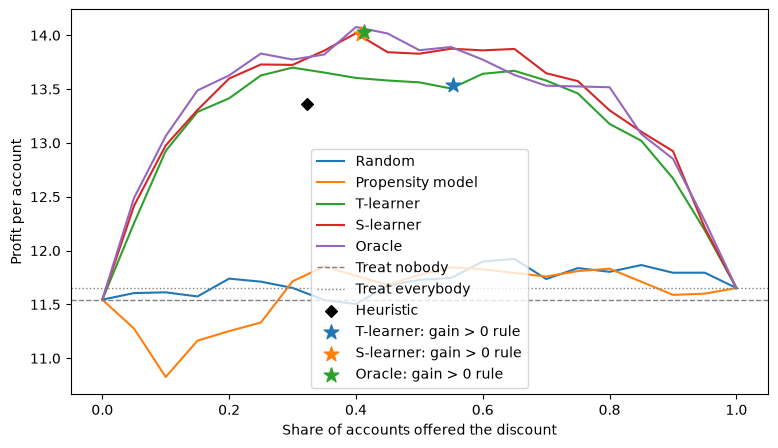

Treat nobody:    11.54
Treat everybody: 11.65
Heuristic:       13.36 (offered to 32% of accounts)
T-learner gain > 0 rule: 13.54 (offered to 55% of accounts)
S-learner gain > 0 rule: 14.02 (offered to 41% of accounts)
Oracle gain > 0 rule: 14.03 (offered to 41% of accounts)


In [4]:
#Lets define a function that calculated profit per account
def avg_profit(policy,Treat,Y,V,d,treat_sh=0.5):
    ind_term = (policy*Treat/treat_sh  * Y * (V-d) + (1-policy) *(1-Treat)/(1-treat_sh) *Y*V)
    return np.mean(ind_term)

n_te          = len(Test)    
treated_test  = Test['treated_i']
y_test        = Test['Y_i']
treated_share = treated_test.mean()
# 1. Trivial policies: treat nobody and treat everybody
profit_nobody   = avg_profit(np.zeros(n_te), treated_test, y_test, V, d,treated_share)
profit_everybody = avg_profit(np.ones(n_te),  treated_test,y_test, V, d,treated_share)    

# 2, 4, 5, 6. Ranking based policies, traced over the share of accounts offered the discount
shares = np.linspace(0, 1, 21)
#print(Test.info())
scores = {'Random': 'score_random',
          'Propensity model': 'propensity_score',
          'T-learner': 'gain_hat_T',
          'S-learner': 'gain_hat_S',
          'Oracle': 'gain_real'}
curves = {}

for name, col in scores.items():
    rank = Test[col].rank(ascending=False, method='first').values   # 1 = highest score
    profits = []
    for s in shares:
        pi = (rank <= round(s*n_te)).astype(int)    # 1 for the top share, 0 for the rest
        profits.append(avg_profit(pi, treated_test, y_test, V, d,treated_share))
    curves[name] = np.array(profits)
  
# 3. Heuristic: a rule, not a ranking, so it is a single point at the share it flags
lo, hi = Train['ln_size_i'].quantile([0.25, 0.75]) 
Test['heuristic'] = ((Test['transtool_i'] == 0) & Test['ln_size_i'].between(lo, hi)).astype(int)
heur_share  = Test['heuristic'].mean()
heur_profit = avg_profit(Test['heuristic'].values, treated_test, y_test, V, d,treated_share)

# No cap view: offer to every account whose estimated gain is positive
rules = {}
for name, col in [('T-learner', 'gain_hat_T'), ('S-learner', 'gain_hat_S'), ('Oracle', 'gain_real')]:
    pi = (Test[col] > 0).astype(int).values
    rules[name] = (pi.mean(), avg_profit(pi, treated_test, y_test, V, d,treated_share))


fig, ax = plt.subplots(figsize=(9, 5))
for name, y in curves.items():
    ax.plot(shares, y, label=name)
ax.axhline(profit_nobody, color='grey', linestyle='--', linewidth=1, label='Treat nobody')
ax.axhline(profit_everybody, color='grey', linestyle=':', linewidth=1, label='Treat everybody')
ax.scatter([heur_share], [heur_profit], marker='D', color='black', label='Heuristic', zorder=3)
for name, (x, y) in rules.items():
    ax.scatter([x], [y], marker='*', s=120, label=f'{name}: gain > 0 rule', zorder=3)
ax.set_xlabel('Share of accounts offered the discount')
ax.set_ylabel('Profit per account')
ax.legend()
plt.savefig("G:/My Drive/Projects/Uplift/qini_curve.png",
            dpi=300, bbox_inches='tight')
plt.show()

# Summary table of the single number policies
print(f'Treat nobody:    {profit_nobody:.2f}')
print(f'Treat everybody: {profit_everybody:.2f}')
print(f'Heuristic:       {heur_profit:.2f} (offered to {heur_share:.0%} of accounts)')
for name, (x, y) in rules.items():
    print(f'{name} gain > 0 rule: {y:.2f} (offered to {x:.0%} of accounts)')

### Results.
1. Treating nobody earns 11.54 per account and treating everybody earns 11.65, so the discount raises adoption by about three points but adds almost no profit when it is given to everyone.
2. Under a budget cap, the propensity model does worst among the model-based rules.
3. When it offers the discount to the top 10 percent of accounts, profit falls to 10.83, below doing nothing and below random targeting, and at 20 percent it earns 11.25, which is still below both. It only reaches the level of treating everybody once 30 to 40 percent of accounts are included, because it spends the early discounts on accounts that would have adopted anyway.
4. At 20 percent of accounts, the T-learner earns 13.41, the S-learner 13.60, and the oracle 13.63. Without a budget cap, the rule that offers the discount to every account with a positive estimated gain earns 14.02 for the S-learner, which matches the oracle's 14.03 and is about 21 percent more than doing nothing.
5. The T-learner rule earns 13.54 and offers the discount to 55 percent of accounts, against 41 percent for the oracle, so it over-offers near the threshold. The simple heuristic earns 13.36 by offering the discount to 32 percent of accounts, which is roughly three quarters of the oracle's gain over doing nothing.
6. In this draw, the T-learner rule and the heuristic are close enough that I would not call one better than the other, so the clearest case for a model is the S-learner rule.

It is also possible to look into this question by feature. Below, I plot the effect for different account sizes. I find that the discount is only worth offering to mid sized accounts. The true expected gain is positive for accounts with annual spend between about 3 and 17 thousand dollars, and it peaks near 9 thousand dollars, where the offer adds about 4.6 of expected profit per account. 

Below 3 thousand dollars, accounts barely respond to the offer, so the discount only gives away margin. Above 17 thousand dollars, the gain turns negative and keeps falling, reaching about -8 for the largest accounts, because these accounts are likely to adopt anyway and the discount is mostly cannibalization. 


The propensity model moves in the opposite direction: the probability of adopting rises steadily with size, from about 5 percent for the smallest accounts to about 26 percent for the largest, so a propensity model ranks the largest accounts first, exactly where the offer loses money. Both learners follow the shape of the true gain. They peak near 8 thousand dollars and turn negative above roughly 20 thousand dollars (T-learner) and 19 thousand dollars (S-learner), slightly later than the true breakeven of 17 thousand dollars, which means they over-offer a little at the margin. These breakevens describe the average account at each size. Whether a specific account is worth discounting also depends on whether it already runs a transformation tool and on its renewal date.

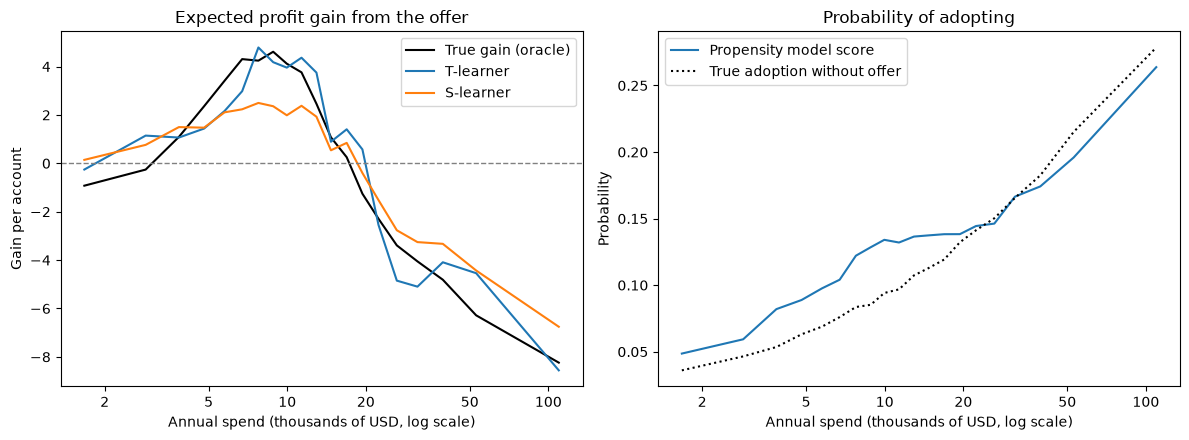

In [5]:
from matplotlib.ticker import FuncFormatter, NullLocator

def plot_vs_feature(feature, df, bins=20, mask=None, title_suffix='', xlabel=None, log_x=False):
    data = df if mask is None else df[mask]
    data = data.assign(bin=pd.qcut(data[feature], bins, duplicates='drop'))
    g = data.groupby('bin', observed=True).agg(x=(feature, 'mean'),
                                               gain_real=('gain_real', 'mean'),
                                               gain_hat_T=('gain_hat_T', 'mean'),
                                               gain_hat_S=('gain_hat_S', 'mean'),
                                               propensity=('propensity_score', 'mean'),
                                               p0_real=('p0_real', 'mean'))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

    # Left: expected profit gain from offering the discount
    axes[0].plot(g['x'], g['gain_real'], label='True gain (oracle)', color='black')
    axes[0].plot(g['x'], g['gain_hat_T'], label='T-learner')
    axes[0].plot(g['x'], g['gain_hat_S'], label='S-learner')
    axes[0].axhline(0, color='grey', linestyle='--', linewidth=1)
    axes[0].set_title('Expected profit gain from the offer' + title_suffix)
    axes[0].set_ylabel('Gain per account')
    axes[0].legend()

    # Right: what the propensity model ranks on
    axes[1].plot(g['x'], g['propensity'], label='Propensity model score')
    axes[1].plot(g['x'], g['p0_real'], label='True adoption without offer', color='black', linestyle=':')
    axes[1].set_title('Probability of adopting' + title_suffix)
    axes[1].set_ylabel('Probability')
    axes[1].legend()

    for ax in axes:
        ax.set_xlabel(xlabel if xlabel is not None else feature)
        if log_x:
            ax.set_xscale('log')
            ax.set_xticks([2, 5, 10, 20, 50, 100])                              # ticks to show (inside the data range)
            ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))  # plain numbers, not powers of ten
            ax.xaxis.set_minor_locator(NullLocator())                           # remove the extra minor ticks
    plt.tight_layout()
    plt.savefig("G:/My Drive/Projects/Uplift/feature_curve.png",
            dpi=300, bbox_inches='tight')
    plt.show()

Test['size_i'] = np.exp(Test['ln_size_i'])    # annual spend in thousands of USD

plot_vs_feature('size_i', Test, xlabel='Annual spend (thousands of USD, log scale)', log_x=True)           # all accounts
#plot_vs_feature('size_i', Test, mask=(Test['transtool_i'] == 0),
#                xlabel='Annual spend (thousands of USD, log scale)', log_x=True,
#                title_suffix=' (no transformation tool)')                               # where the persuadables live